# Robust Shortest-Path Optimization under Urban Congestion

This project investigates route planning on an Amsterdam street network when some locations may be crowded and travel times are uncertain. Three approaches are compared: **explicit area avoidance**, **box-robust routing**, and **budgeted robust routing**. The deterministic shortest path provides a benchmark.

The mathematical models are documented in [the formulation](../docs/model_formulation.md), and numerical comparisons in [the results](../results/README.md).

## 1. Network and deterministic benchmark

The directed street network connects **Bimhuis** (origin) to **Melkweg** (destination). Each edge has a nominal distance, used as a proxy for travel time under a constant-speed assumption. The baseline model selects a shortest route subject to flow conservation.

The utility functions load the network, build the graph inputs, and display the routes.

In [ ]:
from pathlib import Path
import sys

# Allow imports from the repository root when the notebook is opened from notebooks/.
repo_root = Path.cwd()
if not (repo_root / "utils.py").exists():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

import numpy as np
import pyomo.environ as pyo
from utils import (
    get_network, make_instance, get_route, get_distances_to,
    get_crowdedness, plot_network, plot_network_heatmap,
    shortest_path_model,
)

highs_solver = pyo.SolverFactory("appsi_highs")
s = 872644522  # Bimhuis
t = 1299850585  # Melkweg
network = get_network()
nodes, edges, pred, succ = make_instance(network)

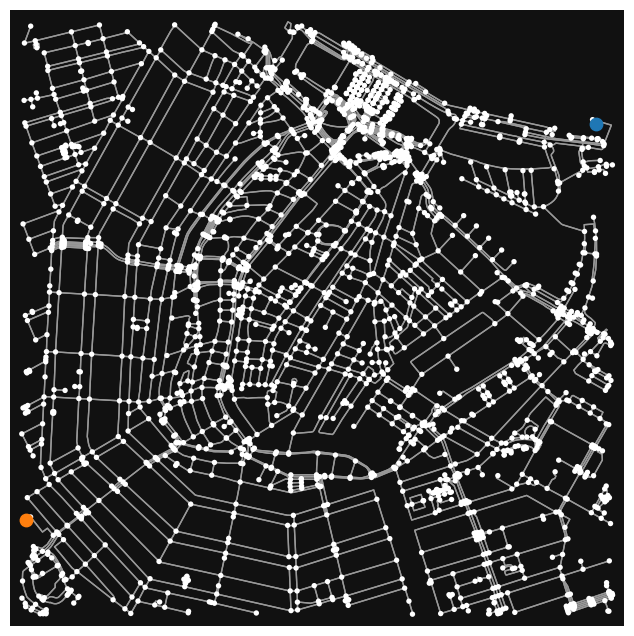

In [30]:
plot_network(network, [s], [t])

The shortest path has length 3352.59


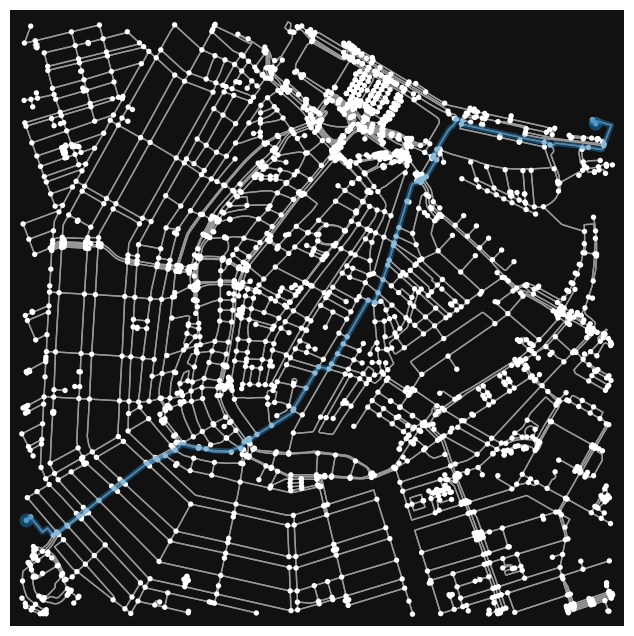

In [33]:
model = shortest_path_model(s, t, nodes, edges, pred, succ)
result = highs_solver.solve(model)
print(f"The shortest path has length {model.total_distance():.2f}")
route = get_route(model)
plot_network(network, route)

## 2. Avoiding a congested area

A location near a crowded hotel is treated as a restricted area. For an avoidance radius $\delta$, nodes within that distance are excluded from the route. Increasing $\delta$ reduces feasible routing options and may force a detour.

In [ ]:
h = 46377925  # Congestion hotspot
dist = get_distances_to(network, h)

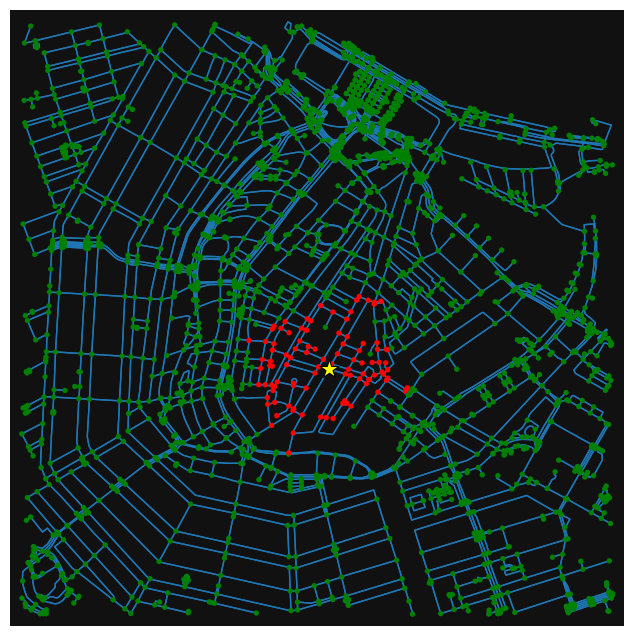

In [34]:
delta = 350
plot_network_heatmap(
    network,
    node_color=["g" if dist[i] >= delta else "r" for i in network.nodes],
    highlight_node=h,
)

### Exclusion-constrained shortest path

The following model extends the deterministic network-flow formulation with constraints preventing traversal through excluded nodes.

In [35]:
def safe_shortest_path_model(s, t, nodes, edges, pred, succ, dist, delta):

    model = shortest_path_model(s, t, nodes, edges, pred, succ)

    model.safe_nodes = pyo.ConstraintList()

    for j in model.nodes:
      if dist[j] <= delta:
        model.safe_nodes.add(model.incoming[j]==0)

        model.safe_nodes.add(model.outgoing[j]==0)

    return model

### Sensitivity to avoidance radius

We solve the model over several radii and compare route lengths and geographical paths.


=== delta = 0 m ===
Shortest safe path length = 3353.89 m


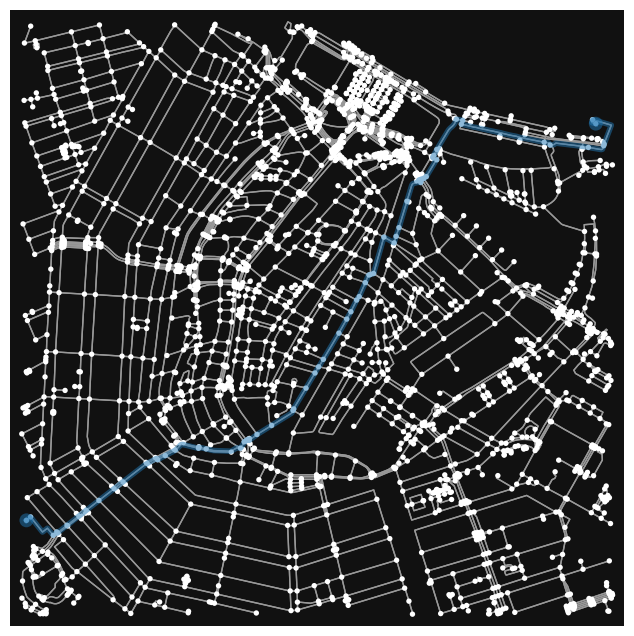


=== delta = 50 m ===
Shortest safe path length = 3421.70 m


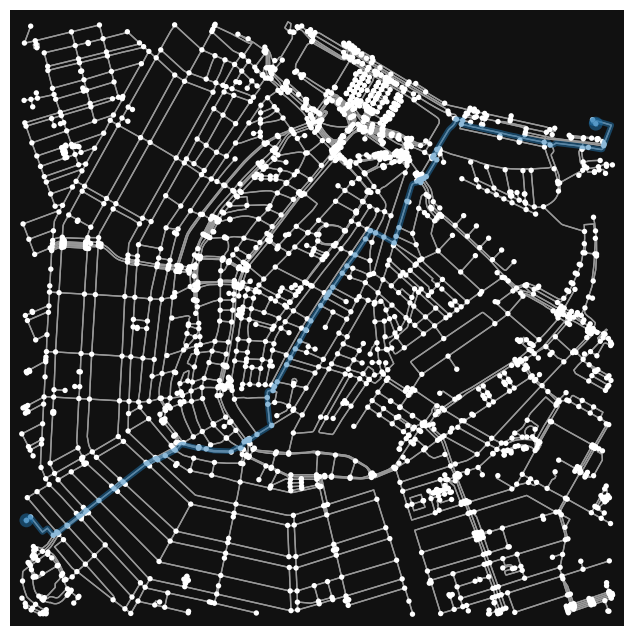


=== delta = 250 m ===
Shortest safe path length = 3424.36 m


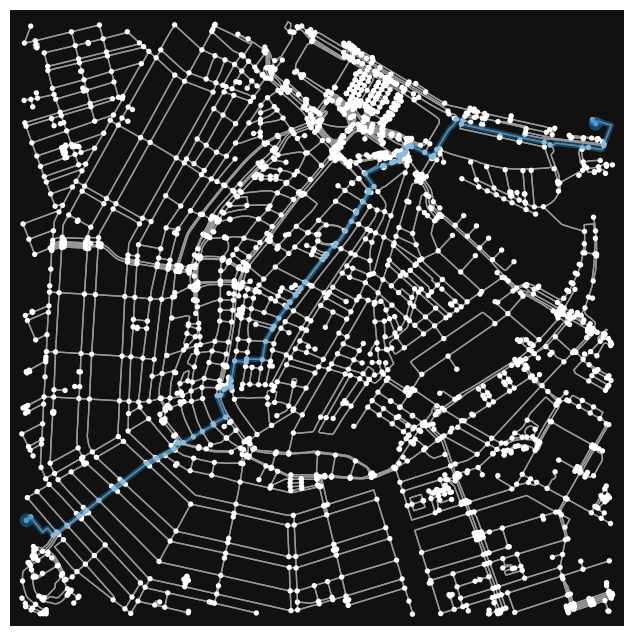


=== delta = 450 m ===
Shortest safe path length = 3426.82 m


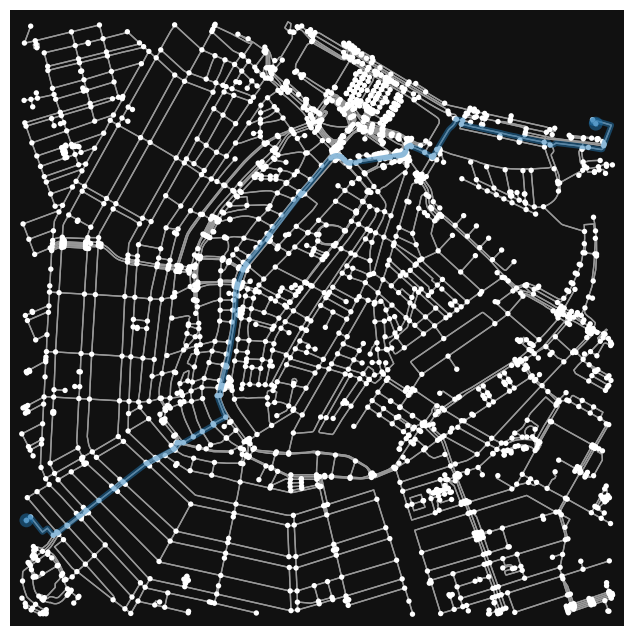


=== delta = 650 m ===
Shortest safe path length = 3508.26 m


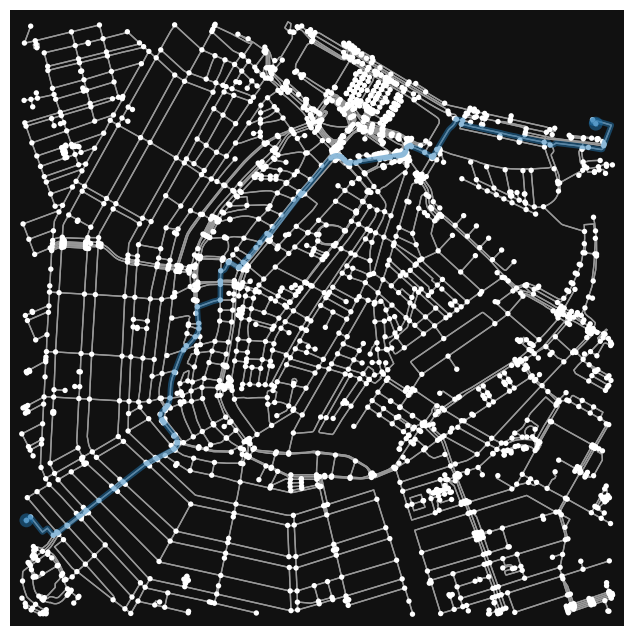


=== delta = 850 m ===
Shortest safe path length = 3755.30 m


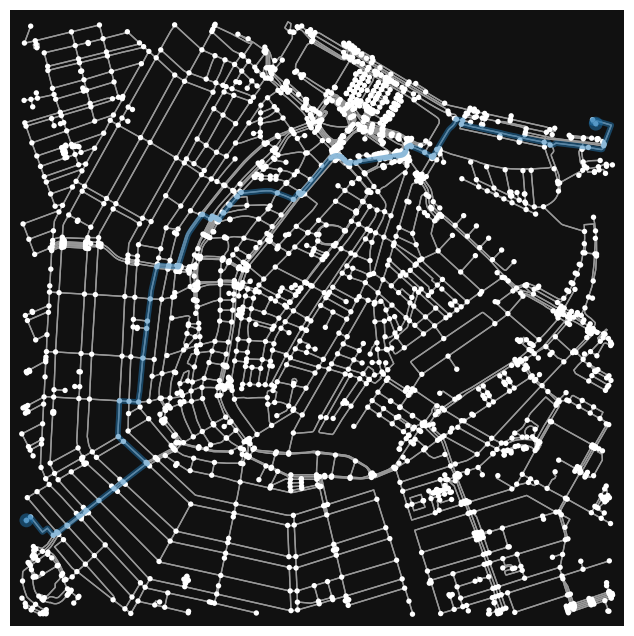


=== delta = 1050 m ===
Shortest safe path length = 4080.59 m


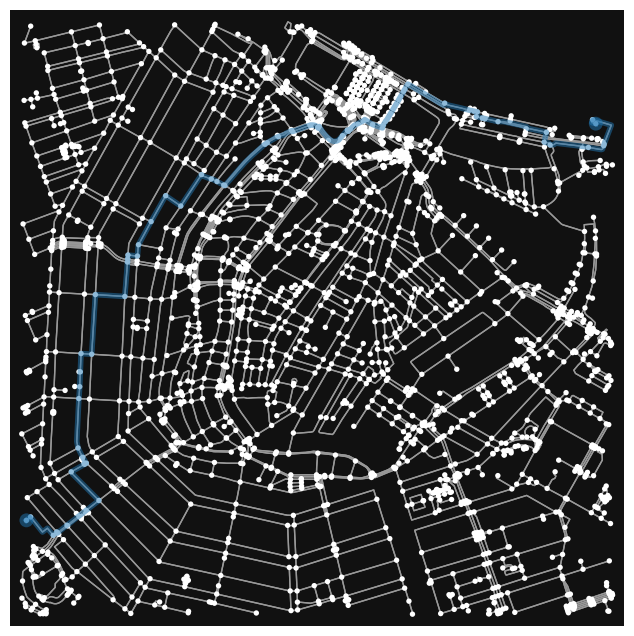

In [36]:
deltas = [0,50,250,450,650,850,1050]

for delta in deltas:
  print(f"\n=== delta = {delta} m ===")
  model = safe_shortest_path_model(s,t,nodes,edges,pred,succ,dist,delta)
  result = highs_solver.solve(model)

  term_cond = result.solver.termination_condition
  if term_cond != pyo.TerminationCondition.optimal:
    print(f"No feasible route found for delta = {delta} (termination: {term_cond})")
    continue

  total_dist = pyo.value(model.total_distance)
  print(f"Shortest safe path length = {total_dist:.2f} m")

  route = get_route(model)
  plot_network(network,route)

As the exclusion radius grows, the available routes become more restricted. The reported route lengths rise from **3,353.89 m** at $\delta=0$ to approximately **4,080 m** at $\delta=1{,}050$. The increase becomes more pronounced at larger radii. See [the result comparison](../results/README.md).

## 3. Robust routing with box uncertainty

Rather than excluding an area entirely, we allow each edge's effective traversal cost to increase with uncertain congestion. The congestion coefficient at each endpoint determines the upper bound for that edge's increase. Box uncertainty protects against the simultaneous worst case on every edge.

The model remains a shortest-path problem after replacing nominal edge costs with their worst-case counterparts.

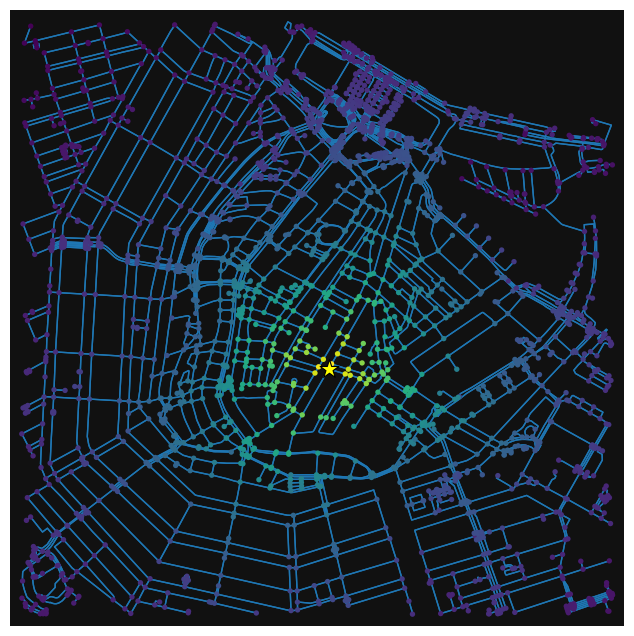

In [37]:
alpha = get_crowdedness(network)
plot_network_heatmap(network, node_color=[alpha[k] for k in nodes], highlight_node=h)

Robust box distance: 4849.18


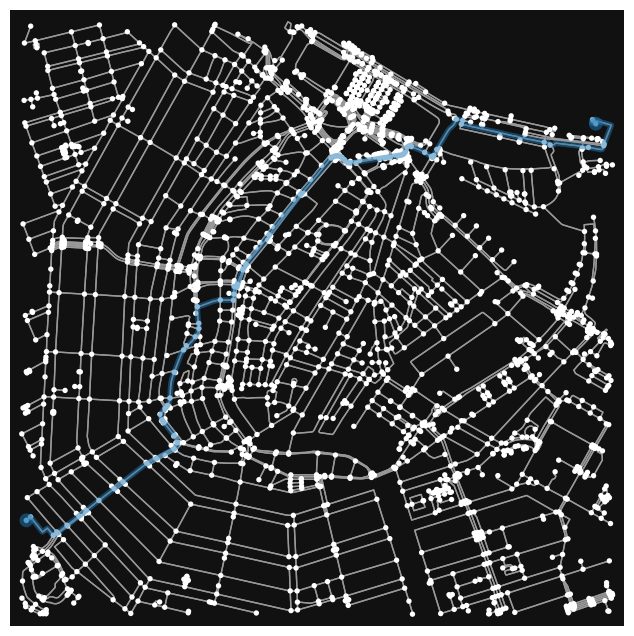

Deterministic distance: 3352.59


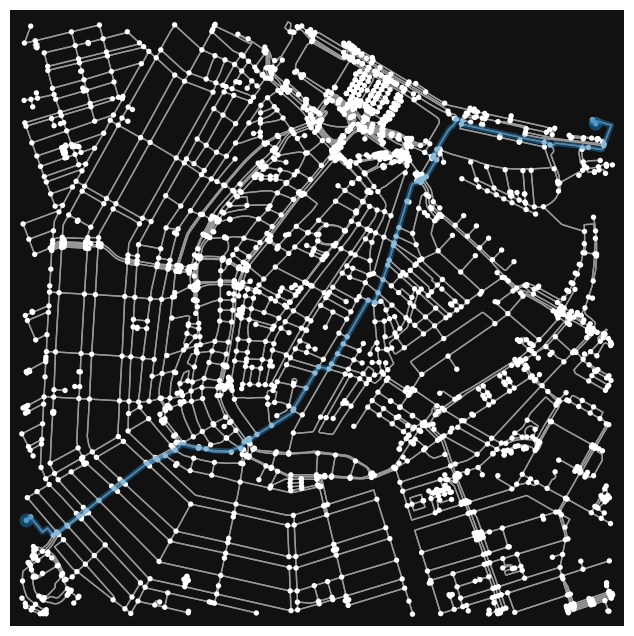

Safe path distance (delta=250): 3424.36


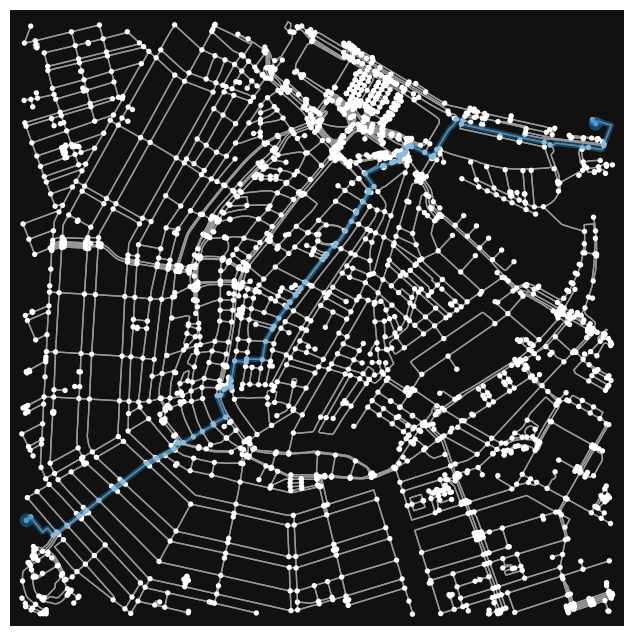

In [38]:
def shortestpath_boxuncertainty(s, t, nodes, edges, pred, succ, alpha):

    robust_edges = {
        (i,j): edges[i,j]*(1 + alpha[i]+ alpha[j])
        for (i,j) in edges
    }

    model = shortest_path_model(s,t,nodes,robust_edges,pred,succ)

    return model

model_box = shortestpath_boxuncertainty(s,t,nodes,edges,pred,succ,alpha)
result = highs_solver.solve(model_box)
print(f"Robust box distance: {pyo.value(model_box.total_distance):.2f}")
route_box = get_route(model_box)
plot_network(network,route_box)

model_det = shortest_path_model(s,t,nodes,edges,pred,succ)
highs_solver.solve(model_det)
dist_det = pyo.value(model_det.total_distance)
route_det = get_route(model_det)
print(f"Deterministic distance: {dist_det:.2f}")
plot_network(network,route_det)

delta = 250
model_safe= safe_shortest_path_model(s,t,nodes,edges,pred,succ,dist,delta)
highs_solver.solve(model_safe)
dist_safe = pyo.value(model_safe.total_distance)
route_safe = get_route(model_safe)
print(f"Safe path distance (delta={delta}): {dist_safe:.2f}")
plot_network(network,route_safe)

The deterministic objective measures nominal network distance, while the box-robust objective includes congestion-adjusted penalties. Consequently, their objective values do not represent identical physical route lengths. The comparison illustrates the trade-off between nominal efficiency and worst-case protection.

## 4. Robust routing with budgeted uncertainty

Box uncertainty can be conservative because it assumes all edge costs can reach their upper bounds simultaneously. A budgeted set constrains the total congestion deviation with the parameter $\Gamma$.

This model uses an auxiliary-variable reformulation that makes the worst-case routing problem tractable as a mixed-integer linear program.

In [39]:
def shortest_path_budgetuncertainty(s,t,nodes,edges,pred,succ,alpha,Gamma):

  model = shortest_path_model(s,t,nodes,edges,pred,succ)

  model.total_distance.deactivate()

  model.lam = pyo.Var(domain=pyo.NonNegativeReals)
  model.q = pyo.Var(model.edges, domain=pyo.NonNegativeReals)
  model.T = pyo.Var(domain=pyo.NonNegativeReals)

  model.Gamma = pyo.Param(initialize=Gamma)

  @model.Constraint()
  def robust_budget(m):
    nominal = sum(edges[i,j]*m.x[i,j] for (i,j) in m.edges)
    budget_term = m.lam*m.Gamma + sum(
      (alpha[i]+alpha[j])*m.q[i,j] for (i,j) in m.edges
  )
    return nominal + budget_term <= m.T

  @model.Constraint(model.edges)
  def lambda_q_bounds(m,i,j):
    return m.lam + m.q[i,j] >= edges[i,j]*m.x[i,j]

  @model.Objective()
  def worst_case_distance(m):
    return m.T

  return model

### Sensitivity to the uncertainty budget

The model is solved for $\Gamma=0,1,\ldots,5$ to examine how the worst-case objective and route selection respond to increasing uncertainty.


=== Gamma = 0 ===
Termination condition:  optimal
Worst case travel time T* = 3352.59


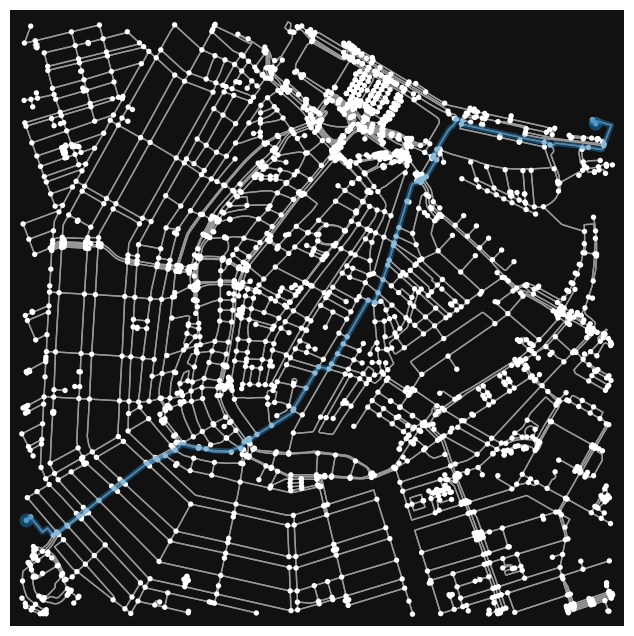


=== Gamma = 1 ===
Termination condition:  optimal
Worst case travel time T* = 3541.17


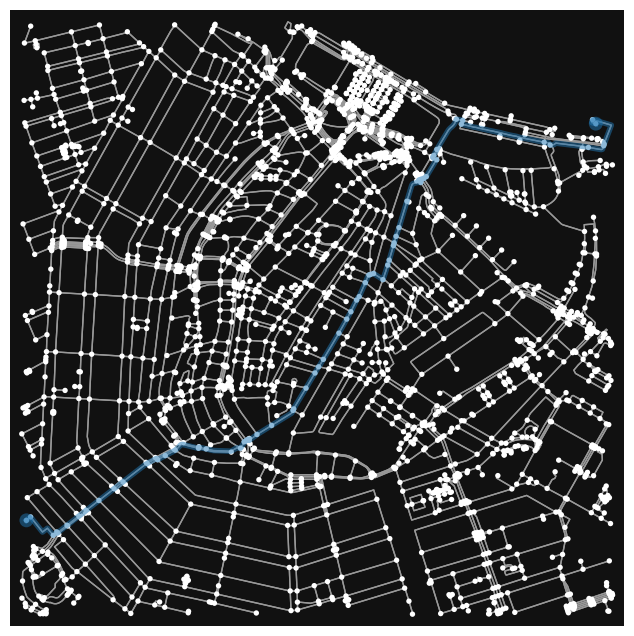


=== Gamma = 2 ===
Termination condition:  optimal
Worst case travel time T* = 3670.86


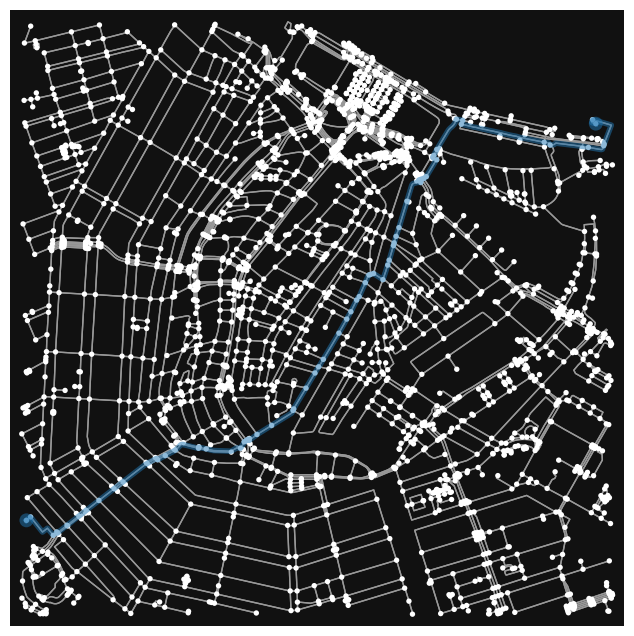


=== Gamma = 3 ===
Termination condition:  optimal
Worst case travel time T* = 3784.10


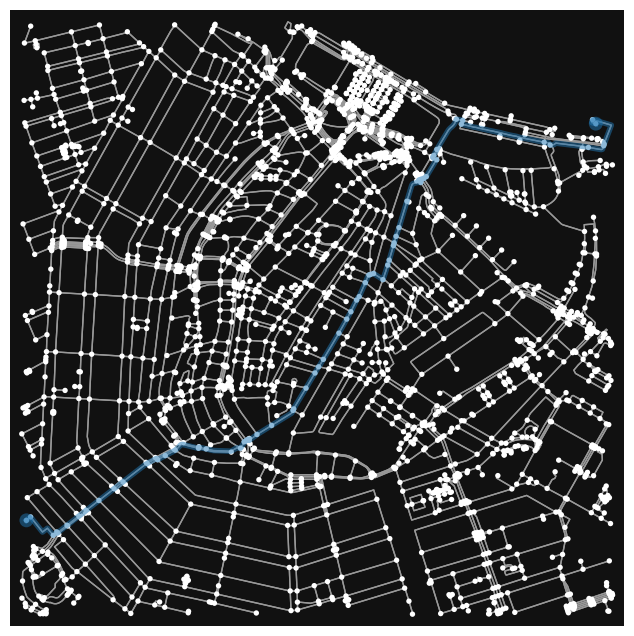


=== Gamma = 4 ===
Termination condition:  optimal
Worst case travel time T* = 3892.52


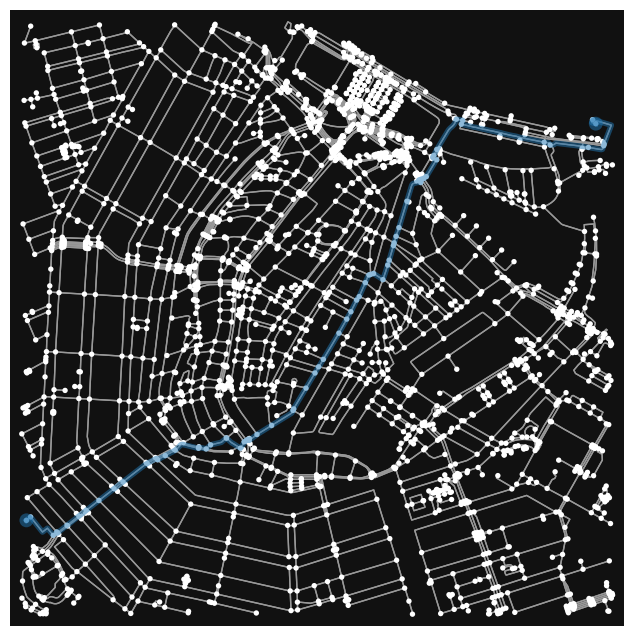


=== Gamma = 5 ===
Termination condition:  optimal
Worst case travel time T* = 3967.22


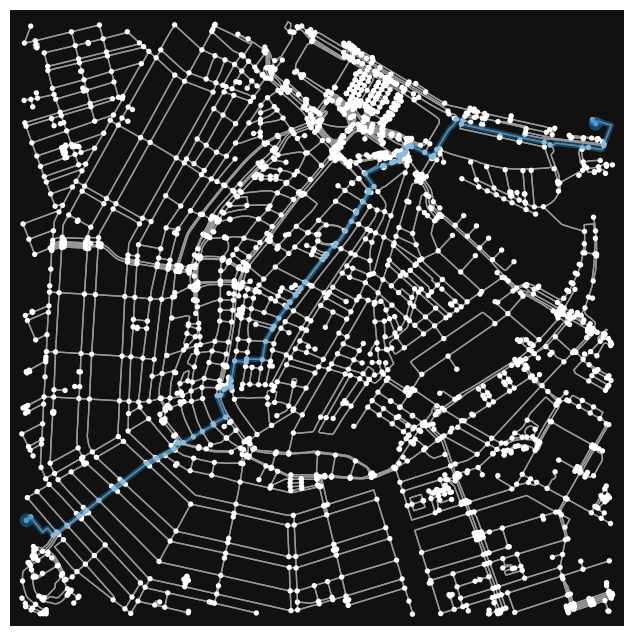

In [40]:
Gammas = [0,1,2,3,4,5]

for Gamma in Gammas:
  print(f"\n=== Gamma = {Gamma} ===")
  model_gamma =shortest_path_budgetuncertainty(s,t,nodes,edges,pred,succ,alpha,Gamma)

  result = highs_solver.solve(model_gamma)

  print("Termination condition: ", result.solver.termination_condition)

  if result.solver.termination_condition != pyo.TerminationCondition.optimal:
    print("No optimal solution found")
    continue


  T_star = pyo.value(model_gamma.T)
  print(f"Worst case travel time T* = {T_star:.2f}")

  route_gamma = get_route(model_gamma)
  plot_network(network, route_gamma)

The reported worst-case objective increases from **3,352.59** at $\Gamma=0$ to **3,967.22** at $\Gamma=5$. In the tested scenarios, the chosen route remains essentially the same, although its robust cost increases.

For the complete comparison and interpretation, see [Results](../results/README.md).

## 5. Key observations

- Explicit exclusion trades shorter routes for geographic separation from the hotspot.
- Box uncertainty penalizes all potentially congested edges at their maximum permitted levels.
- Budgeted uncertainty makes the degree of conservatism adjustable through $\Gamma$.

These approaches address the same routing problem with different assumptions about congestion, rather than treating them as separate exercises.